In [1]:
import jax
import os

import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/Documents/Research/Projects/sensitive-gates-2/pulse-simulator/.venv/lib/python3.12/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [2]:
from datetime import datetime
import numpy as np
import pickle as pkl

import qiskit as qk
from qiskit.quantum_info import Operator
from qiskit import pulse
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d

from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm, logm
from tqdm import tqdm

import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib as mpl

In [3]:
# Config stuff
jax.config.update("jax_enable_x64", True)

os.environ["JAX_PLATFORM_NAME"] = "gpu"

# Set the memory fraction if gpu]
if jax.default_backend() == "gpu":
    print("Setting memory fraction.")
    os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]="0.49"

qk_d.array.Array.set_default_backend("jax")

# Check if GPU is available
jax.default_backend()

Setting memory fraction.


'gpu'

# Pulses

In [4]:
num_qubits = 4

coupling_map = (
    [[i, i + 1] for i in range(0, num_qubits - 1)] 
    + [[i + 1, i] for i in range(0, num_qubits - 1)]
)
# coupling_map += [[0, num_qubits - 1], [num_qubits - 1, 0]]

backend = qk_fp.GenericBackendV2(
    num_qubits=num_qubits,
    basis_gates=["id", "rz", "sx", "x", "ecr"],
    coupling_map=coupling_map,
    seed=17,
)

# backend = qk_fp.FakeMumbai()
# backend = qk_fp.FakeManila()

In [5]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

dt = 0.5  # backend.configuration().dt * ns
desired_1qb_duration = 120  # dt
desired_2qb_duration_default = 120 * 4  # dt

# ignore granularity restriction
duration_1qb = desired_1qb_duration
duration_2qb_default = desired_2qb_duration_default

# Gate time (granularity restriction)
# duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration)
# duration_2qb_default = ps.qiskit_closest_multiple_of_16(desired_2qb_duration_default)

# Pulses

This section should be re-run with the simulator, as needed.

In [6]:
fname_2qb = "../pulse_simulator/gatesets/ecr_swpt_zx_0.023390909090909087_ix_0.0083_Δt_1.0_robust.csv"
ecr_a = ps.from_csv(fname_2qb, delimiter=",")

In [7]:
# 1qb shapes
# ==========

names_1qb_a = ["X1", "X2", "SX1", "SX2", "ID1", "ID2"]
fname_1qb_a = "../pulse_simulator/gatesets/controls_v3_T_120_dt_0.5_a_0.35_dda_0.03.csv"
pico_a = ps.from_csv(fname_1qb_a, delimiter="\t")
pico_a = np.vstack([pico_a, 1.0 * np.ones(pico_a.shape[1])])
angles_1qb_a = [np.pi / 2, np.pi / 2, np.pi / 4, np.pi / 4, np.pi, 0.0]

cal_1qb_robust = ps.calibrate_gateset(
    gateset=pico_a,
    names=names_1qb_a,
    angles=angles_1qb_a,
    duration=duration_1qb,
    dt=dt,
    samples=60,
)

names_1qb_b = ["X1", "SX1", "X2", "SX2", "ID1", "ID2"]
fname_1qb_b = "../pulse_simulator/gatesets/dephasing-robust-x-sx-gates_a0.5_da0.25_dda0.0125_R0.001_T120_Δt0.5.csv"
pico_b = ps.from_csv(fname_1qb_b, delimiter=",")
pico_b = np.vstack([pico_b, pico_b, 1.0 * np.ones(pico_b.shape[1]), 1.0 * np.ones(pico_b.shape[1])])
angles_1qb_b = [np.pi / 2, np.pi / 4, np.pi / 2,  np.pi / 4, 0.0, 0.0]

cal_1qb_dephasing = ps.calibrate_gateset(
    gateset=pico_b,
    names=names_1qb_b,
    angles=angles_1qb_b,
    duration=duration_1qb,
    dt=dt,
    samples=60,
)

# defaults
cal_1qb_default = ps.default_single_qubit_gateset(
    names_1qb_a,
    duration_1qb,
    dt,
)

# 2qb shapes <- These must change with J

Storing symbolic pulses...
Adjusting X1 by amplitude  0.50 for rotation angle  0.50π
Adjusting X2 by amplitude  0.50 for rotation angle  0.50π
Adjusting SX1 by amplitude  0.50 for rotation angle  0.25π
Adjusting SX2 by amplitude  0.50 for rotation angle  0.25π
Adjusting ID1 by amplitude  0.50 for rotation angle  1.00π
Adjusting ID2 by amplitude  0.00 for rotation angle  0.00π
Storing symbolic pulses...
Adjusting X1 by amplitude  0.50 for rotation angle  0.50π
Adjusting SX1 by amplitude  0.50 for rotation angle  0.25π
Adjusting X2 by amplitude  0.50 for rotation angle  0.50π
Adjusting SX2 by amplitude  0.50 for rotation angle  0.25π
Adjusting ID1 by amplitude  0.00 for rotation angle  0.00π
Adjusting ID2 by amplitude  0.00 for rotation angle  0.00π


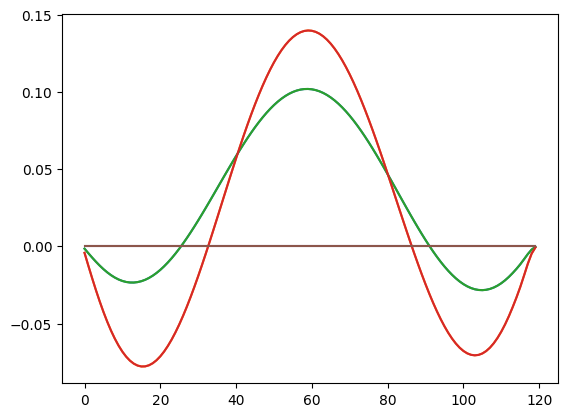

In [13]:
for key, val in cal_1qb_dephasing.items():
    plt.plot(ps.get_samples(val).real)

/tmp/ipykernel_488561/3109539594.py:44: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  grayscale_colors = [cm.get_cmap("Greys", 9)(i) for i in [3, 5, 9]]


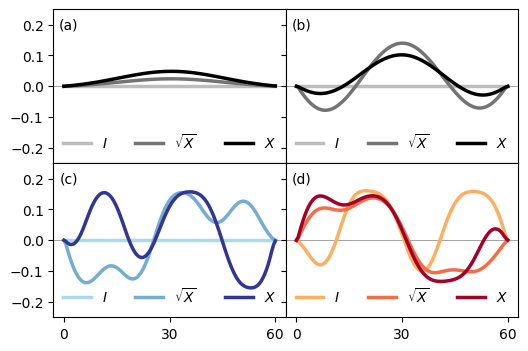

In [150]:
t = np.linspace(0, duration_1qb, 121, endpoint=True)


fig, axes = plt.subplots(2, 2, figsize=(6., 4))

# set wspace and hspace
fig.subplots_adjust(wspace=0.0, hspace=0.0)

for ax in axes.flatten():
    ax.set_xticks([0, 60, 120])
    ax.set_xticklabels([0, 30, 60])

    ax.set_ylim([-0.25, 0.25])
    ax.set_yticks([-0.2, -0.1, 0, 0.1, 0.2])

    # horizontal grid
    # ax.grid(True, which="major", axis="y")
    ax.axhline(0, color="black", lw=0.5, alpha=0.5)
    # ax.axhline(-.1, color="black", lw=0.5, alpha=0.5)
    # ax.axhline(.1, color="black", lw=0.5, alpha=0.5)
    # ax.axhline(-.2, color="black", lw=0.5, alpha=0.5)
    # ax.axhline(.2, color="black", lw=0.5, alpha=0.5)

# Add text label to inside of axes for each subplot
for i, ax in enumerate(axes.flatten()):
    ax.text(
        0.066,
        0.9,
        ["(a)", "(b)", "(c)", "(d)"][i],
        horizontalalignment="center",
        verticalalignment="center",
        transform=ax.transAxes,
        fontsize=10,
    )

for ax in axes[:, 1:].flatten():
    ax.set_yticklabels([])

for ax in axes[:-1, :].flatten():
    ax.set_xticklabels([])

# colors for default
# 3 grayscale
grayscale_colors = [cm.get_cmap("Greys", 9)(i) for i in [3, 5, 9]]

key_lookup = {
    "X1": r"$X$",
    "SX1": r"$\sqrt{X}$",
    "X2": r"$X$",
    "SX2": r"$\sqrt{X}$",
    "ID1": r"$I$",
    "ID2": r"$I$",
}

ax = axes[0, 0]
i = 0
for key, val in reversed(cal_1qb_default.items()):
    if "1" in key:
        y = np.hstack([[0], ps.get_samples(val).real])
        ax.plot(t, y, color=grayscale_colors[i], lw=2.5, label=key_lookup[key])
        i += 1
# remove frame
ax.legend(ncol=3, loc="lower center", frameon=False) 

ax = axes[0, 1]
i = 0
for key, val in reversed(cal_1qb_dephasing.items()):
    if "1" in key:
        y = np.hstack([[0], ps.get_samples(val).real])
        ax.plot(t, y, color=grayscale_colors[i], lw=2.5, label=key_lookup[key])
        i += 1
ax.legend(ncol=3, loc="lower center", frameon=False) 
    
ax = axes[1, 0]
order = ["X1", "SX1", "X2", "SX2", "ID1", "ID2"]
blue_colors = ["#abd9e9ff", "#74add1ff", "#313695ff"]
i = 0
for key, val in reversed(cal_1qb_robust.items()):
    if "2" in key:
        y = np.hstack([[0], ps.get_samples(val).real])
        ax.plot(t, y, lw=2.5, color=blue_colors[i], label=key_lookup[key])
        i += 1
ax.legend(ncol=3, loc="lower center", frameon=False)

ax = axes[1, 1]
order = ["X1", "SX1", "X2", "SX2", "ID1", "ID2"]
red_colors = ["#fdae61ff", "#f46d43ff", "#a50026ff"]
i = 0
for key, val in reversed(cal_1qb_robust.items()):
    if "1" in key:
        y = np.hstack([[0], ps.get_samples(val).real])
        ax.plot(t, y, lw=2.5, color=red_colors[i], label=key_lookup[key])
        i += 1
ax.legend(ncol=3, loc="lower center", frameon=False)

# save figure for paper
fig.savefig("../images/single_qubit_gates.pdf", bbox_inches="tight", dpi=300, transparent=True)

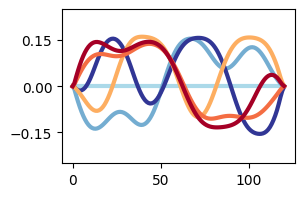

In [158]:
fig, ax = plt.subplots(1, 1, figsize=(3., 2))

ax.set_ylim([-0.25, 0.25])
ax.set_yticks([-0.15, 0, 0.15])

order = ["X1", "SX1", "X2", "SX2", "ID1", "ID2"]
blue_colors = ["#abd9e9ff", "#74add1ff", "#313695ff"]
i = 0
for key, val in reversed(cal_1qb_robust.items()):
    if "2" in key:
        y = np.hstack([[0], ps.get_samples(val).real])
        ax.plot(t, y, lw=3, color=blue_colors[i], label=key_lookup[key])
        i += 1
# ax.legend(ncol=3, loc="lower center", frameon=False)

order = ["X1", "SX1", "X2", "SX2", "ID1", "ID2"]
red_colors = ["#fdae61ff", "#f46d43ff", "#a50026ff"]
i = 0
for key, val in reversed(cal_1qb_robust.items()):
    if "1" in key:
        y = np.hstack([[0], ps.get_samples(val).real])
        ax.plot(t, y, lw=3, color=red_colors[i], label=key_lookup[key])
        i += 1
# ax.legend(ncol=3, loc="lower center", frameon=False)

# save figure for paper
fig.savefig("../images/crosstalk-robust-gateset.pdf", bbox_inches="tight", dpi=300, transparent=True)

In [109]:
# plt.plot(ps.get_samples(cal_1qb_dephasing["X1"]))
# plt.plot(ps.get_samples(cal_1qb_dephasing["SX1"]))

# Circuits

### Ising

In [159]:
registers = [0, 1, 2, 3]
ising = ps.TransverseIsingModel(quantum_registers=registers)
# circ = ising.second_order_Trotter_unitary()
circ = ising.first_order_Trotter_unitary()

# transpile circuit
# circ2 = qk.transpile(circ, backend=backend, optimization_level=0)
# fig = circ2.draw('mpl')
# fig.savefig("/home/andy/Documents/Research/Projects/robust-gatesets/playground/ising_circuit.pdf", bbox_inches="tight", transparent=True, dpi=300)
# circ2.draw('mpl')


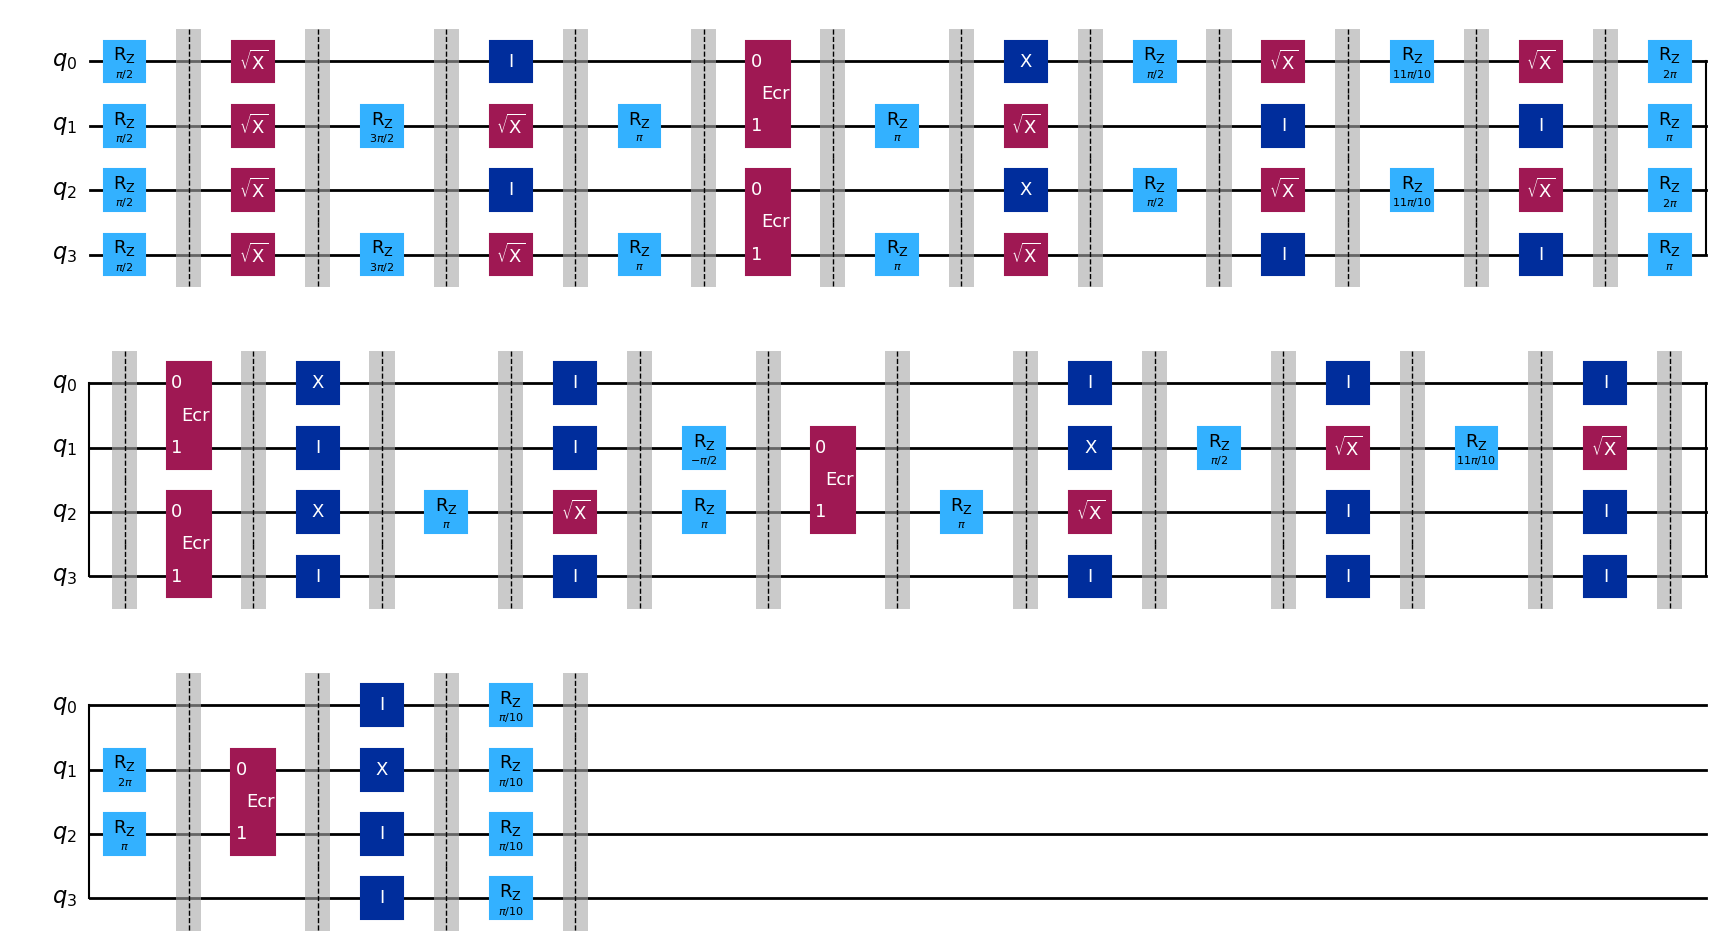

In [23]:
# simulator = ps.Simulator(registers, backend)
# circ1 = simulator.build_circuit(moments=simulator.build_moments(circ), insert_barriers=True)
# # fig = circ1.draw("mpl")
# # fig.savefig("/home/andy/Documents/Research/Projects/robust-gatesets/playground/transpiled_circuit.pdf", bbox_inches="tight", transparent=True, dpi=300)
# circ1.draw("mpl")


#### Remove 2QB

In [ ]:
new_moments = []
for moment in simulator.build_moments(circ):
    if ps.get_moment_case(moment) == "ecr":
        continue
    else:
        new_moments.append(moment)

circ2 = simulator.build_circuit(moments=new_moments, insert_barriers=True)

In [ ]:
# circ1.draw('mpl')
circ2.draw('mpl')

### Random Circuit

In [ ]:
from qiskit.circuit.random import random_circuit

In [ ]:
sim_tester.build_circuit(moments=sim_tester.build_moments(circXY4_draw1), insert_barriers=True).draw('mpl')

In [ ]:
registers = [0, 1]
simulator = ps.Simulator(registers, backend)

depth = 10
rand_circ = random_circuit(len(registers), depth=depth, seed=17, max_operands=2)
circ3 = simulator.build_circuit(moments=simulator.build_moments(rand_circ), insert_barriers=True)
circ3.draw('mpl')

### Simulataneous XY4

In [168]:
def prepare_state(circ, registers, inverse=False):
    # [circ.h(r) for r in registers]
    if inverse:
        [circ.sx(r).inverse() for r in registers]
    else:
        [circ.sx(r) for r in registers]

def apply_xy4(circ, q, invert=False):
    circ.x(q)
    circ.y(q)
    circ.x(q)
    circ.y(q)
        
def apply_symmetric_xy4(circ, q):
    # X
    circ.x(q)
    # Y
    circ.rz(-np.pi / 2, q)
    circ.x(q)
    circ.rz(np.pi / 2, q)
    # X
    circ.x(q)
    # Y
    circ.rz(-np.pi / 2, q)
    circ.x(q)
    circ.rz(np.pi / 2, q)

def apply_asymmetric_xy4(circ, q, angle=np.pi/2):
    # X
    circ.x(q)
    # Y
    circ.rz(np.pi - angle, q)
    circ.x(q)
    circ.rz(-angle, q)
    # X
    circ.x(q)
    # Y
    circ.rz(np.pi - angle, q)
    circ.x(q)
    circ.rz(-angle, q)

def apply_reverse_xy4(circ, q, invert=False):
    if invert:
        circ.y(q)
        circ.x(q)
        circ.y(q)
        circ.x(q)
    else:
        apply_xy4(circ, q)

def apply_simultaneous_xy4(registers, layers=1, verbose=False):
    circ1 = qk.QuantumCircuit(len(registers))
    circ2 = qk.QuantumCircuit(len(registers))
    circ3 = qk.QuantumCircuit(len(registers))
    prepare_state(circ1, registers)
    prepare_state(circ2, registers)
    prepare_state(circ3, registers)
    for _ in range(layers):
        for r in registers:
            apply_xy4(circ1, r)
            apply_asymmetric_xy4(circ2, r, angle=np.pi/2)
            apply_asymmetric_xy4(circ3, r, angle=np.pi/4)
            # apply_reverse_xy4(circ3, r, invert=r%2==0)
    # prepare_state(circ1, registers, inverse=True)
    # prepare_state(circ2, registers, inverse=True)
    # prepare_state(circ3, registers, inverse=True)
    return circ1, circ2, circ3

# -------------------------

xy4_registers = [0, 1] #[2, 3]

measure_XY4_circ = qk.QuantumCircuit(len(xy4_registers))
prepare_state(measure_XY4_circ, xy4_registers, inverse=True)

circXY4_1, circXY4_2, circXY4_3 = apply_simultaneous_xy4(xy4_registers, layers=200)
circXY4_draw1, circXY4_draw2, circXY4_draw3 = apply_simultaneous_xy4(xy4_registers, layers=1)

##### How many moments in layer?

In [161]:
circXY4_zero,_,_ = apply_simultaneous_xy4([0, 1], layers=0)
circXY4_one,_,_ = apply_simultaneous_xy4([0, 1], layers=1)

In [162]:
sim_tester = ps.Simulator([0, 1], backend)

In [163]:
len(simulator.build_moments(circXY4_one)) - len(simulator.build_moments(circXY4_zero))

NameError: name 'simulator' is not defined

In [ ]:
simulator.build_moments(circXY4_one)

##### Three definitions of Y

In [164]:
c = qk.QuantumCircuit(1)
c.rz(-np.pi / 2, 0)
c.x(0)
c.rz(np.pi / 2, 0)
# c.draw('mpl')
qk.quantum_info.Operator.from_circuit(c)

Operator([[0.00000000e+00+0.j, 2.22044605e-16-1.j],
          [2.22044605e-16+1.j, 0.00000000e+00+0.j]],
         input_dims=(2,), output_dims=(2,))


In [165]:
c = qk.QuantumCircuit(1)
c.rz(-np.pi, 0)
c.x(0)
# c.draw('mpl')
qk.quantum_info.Operator.from_circuit(c)

Operator([[0.000000e+00+0.j, 6.123234e-17-1.j],
          [6.123234e-17+1.j, 0.000000e+00+0.j]],
         input_dims=(2,), output_dims=(2,))


In [166]:
c = qk.QuantumCircuit(1)
c.y(0)
# c.draw('mpl')
qk.quantum_info.Operator.from_circuit(c) 

Operator([[0.+0.j, 0.-1.j],
          [0.+1.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


##### Check fidelities of short circuits

In [ ]:
op1 = np.array(qk.quantum_info.Operator.from_circuit(circXY4_draw1).data)
op2 = np.array(qk.quantum_info.Operator.from_circuit(circXY4_draw2).data)
op3 = np.array(qk.quantum_info.Operator.from_circuit(circXY4_draw3).data)

np.isclose(op1, op2), np.isclose(op2, op3), np.isclose(op1, op3)
# ps.operator_fidelity(op1, op2), ps.operator_fidelity(op2, op3), ps.operator_fidelity(op1, op3)

In [ ]:
op1

In [ ]:
op2

In [ ]:
op3

##### Inspect XY4 RZ placement

In [ ]:
sim_tester = ps.Simulator(xy4_registers, backend)

In [ ]:
circXY4_draw1

In [ ]:
sim_tester.build_circuit(moments=sim_tester.build_moments(circXY4_draw1), insert_barriers=True).draw('mpl')

In [ ]:
sim_tester.build_circuit(moments=sim_tester.build_moments(circXY4_draw2), insert_barriers=True).draw('mpl')

In [ ]:
sim_tester.build_circuit(moments=sim_tester.build_moments(circXY4_draw3), insert_barriers=True).draw('mpl')

### RB Circuit [[link](https://qiskit-community.github.io/qiskit-experiments/manuals/verification/randomized_benchmarking.html)]

In [ ]:
from qiskit_experiments.library import StandardRB

In [ ]:
registers = [0, 1]#, 2] #, 3]
seeds = [17, 18]#, 19] #, 20]
simulator = ps.Simulator(registers, backend)
simult_rb = qk.QuantumCircuit(len(registers))

for r, seed in zip(registers, seeds):
    # Create an RB experiment
    lengths = [10]
    rb_exp = StandardRB([0], lengths, num_samples=1, seed=seed)
    rb_circ = qk.transpile(rb_exp.circuits()[0], backend, optimization_level=1)

    rb_circ = ps.remove_final_measurement(ps.remove_idle_wires(rb_circ))
    # rb_circ.draw(output="mpl")
    simult_rb.compose(rb_circ, qubits=r, inplace=True)

simult_rb = simulator.build_circuit(moments=simulator.build_moments(simult_rb), insert_barriers=True)
simult_rb.draw('mpl')

# Simulator

In this example, we loop over the one and two qubit gatesets.

You can make changes to the simulator's random variable params between runs, instead of changing the actual simulator variables.

This is because actually using the sampled values for crosstalk required thinking about frequency layouts, which I did not want to do.

It is important to turn on decoherence if we want to see the advantages for the 2QB gate reduction.

In [170]:
sampler = ps.BackendSampler(1e9)
J12 = sampler.frequency_units(sampler.draw_coupling(mean=True), angular=True)
α = sampler.frequency_units(sampler.draw_anharmonicity(mean=True), angular=True)
Δ12 = sampler.frequency_units(sampler.draw_frequency(std=True), angular=True)
2 * α * J12**2 / (Δ12**2 - α**2) # Note units!

0.0001371984375703721

In [193]:
def get_ix_coef(simlator, J_factor=1.0):
    J = J_factor * simlator._backend_sampler.frequency_units(sampler.draw_coupling(mean=True), angular=True)
    αc = simlator._backend_sampler.frequency_units(sampler.draw_anharmonicity(mean=True), angular=True)
    Δct = simlator._backend_sampler.frequency_units(sampler.draw_frequency(std=True), angular=True)
    return -J / (Δct + αc)

def get_zz_coef(simlator, J_factor=1.0):
    J = J_factor * simlator._backend_sampler.frequency_units(sampler.draw_coupling(mean=True), angular=True)
    αc = simlator._backend_sampler.frequency_units(sampler.draw_anharmonicity(mean=True), angular=True)
    Δct = simlator._backend_sampler.frequency_units(sampler.draw_frequency(std=True), angular=True)
    return 2 * αc * J**2 / (Δct**2 - αc**2) # Note units!

In [194]:
get_zz_coef(simulator), get_ix_coef(simulator)

(0.0001371984375703721, 0.0086)

In [217]:
save_data = False

registers = [0, 1]
circuits = [circXY4_1]
circuit_names = ["XY4-def."] #, "XY4-sym.", "XY4-asym."]
J_inputs = [1.21]

# registers = [0, 1, 2, 3]
# circuits = [circ1]
# circuit_names = ["TFIM"]
# J_inputs = [0.5, 1.0, 1.5, 2.0, 4.0]

include_crosstalk = True
include_dissipation = True
using_two_qubit_gates = False
model_name = "SWPT"

total_data = []

J_save_x = {}

for circ_i, circ in enumerate(circuits):

    now = datetime.now()
    dt_string = now.strftime("%Y-%m-%d_%H-%M-%S")
    if len(circuits) > 1:
        dt_string = f"{dt_string}_circ{circ_i}"

    simulator = ps.Simulator(registers, backend)
    J_default = simulator._backend_sampler.params["coupling"]["mean"]
    print(f"J default: {J_default}")

    J_results = []
    J_save_x[circ_i] = []

    for J_factor in J_inputs:
        print(f"J factor: {J_factor}, ZZ value: {get_zz_coef(simulator, J_factor=J_factor)}")
        # --------------------------------
        simulator._backend_sampler.params["coupling"]["mean"] = J_default * J_factor

        if using_two_qubit_gates:
            # NOTE: 2QB duration should change with J!
            duration_2qb = duration_2qb_default / J_factor
            print(f"\tDuration should change: {duration_2qb}")

            angle = ps.two_qubit_models.calibrate_default_cross_resonance_drive(
                model_name, sampler=simulator._backend_sampler
            )
            print(f"\tAngle should change: {angle}")

            gates_2qb = {"+": angle, "-": -angle}
            cal_2qb = ps.default_gateset(gates_2qb, duration_2qb, dt)

            amplitude = np.max(ps.get_samples(cal_2qb["+"]).real)
            print(f"\tAmplitude should stay the same: {amplitude}")

            # NOTE: this wouldn't actually work on hardware... but it's a start
            # The point here is that
            cal_2qb_robust = ps.calibrate_gateset(
                gateset=np.vstack([ecr_a[1, :], -ecr_a[1, :]]),
                names=["+", "-"],
                angles=[angle, -angle],
                duration=duration_2qb,
                dt=dt,
                samples=60,
            )
            
            # J / (Δct + αc) # NOTE: Bug here, was missing J_factor!
            c_ix = get_ix_coef(simulator, J_factor=J_factor)
            cal_2qb_rotary = ps.calibrate_gateset(
                gateset=np.vstack([ecr_a[1, :], -ecr_a[1, :]]),
                names=["+", "-"],
                angles=[-angle * c_ix, angle * c_ix],
                duration=duration_2qb,
                dt=dt,
                samples=60,
            )

            rotary_2qb = ps.default_gateset({"+": np.pi, "-": -np.pi}, duration_2qb, dt)

            cases = [
                # "1-default, 2-default", 
                # "1-crosstalk, 2-default", 
                # "1-default, 2-rotary",
                # "1-dephasing, 2-rotary",
                # "1-crosstalk, 2-rotary",
                # "1-crosstalk, 2-robust",
                "decoherence limit"
            ]
            gateset_pairs = [
                # [cal_1qb_default, [cal_2qb, None]],
                # [cal_1qb_robust, [cal_2qb, None]],
                # [cal_1qb_default, [cal_2qb, rotary_2qb]],
                # [cal_1qb_dephasing, [cal_2qb, rotary_2qb]],
                # [cal_1qb_robust, [cal_2qb, rotary_2qb]],
                # [cal_1qb_robust, [cal_2qb_robust, cal_2qb_rotary]], # NOTE: Should we just cheat and use the error-free gate?
                [cal_1qb_default, [cal_2qb, None]],
            ]
        else:
            duration_2qb = duration_2qb_default
            cases = [
                # "1-crosstalk", 
                # "1-dephasing",
                "1-default",
            ]
            gateset_pairs = [
                # [cal_1qb_robust, [None, None]],
                # [cal_1qb_dephasing, [None, None]],
                [cal_1qb_default, [None, None]],
            ]

        # --------------------------------

        fidelities = {}

        # Create directory
        if save_data:
            directory = (
                f"../playground/data_{dt_string}/"
                + f"J_{J_factor}_crosstalk_{include_crosstalk}_dissipation_{include_dissipation}"
            )
            os.makedirs(directory)

        for case, pair in zip(cases, gateset_pairs):
            gateset1, gateset2s = pair
            gateset2, rotary2 = gateset2s

            # res, ops = 
            ops = None
            if case == "decoherence limit":
                res = simulator.simulate_circuit(
                    circ,
                    gateset1,
                    gateset2,
                    dt,
                    include_crosstalk=False,
                    include_dissipation=include_dissipation,
                    insert_identities=True,
                    cross_resonance_model_name=model_name,
                    gpu=True,
                    rotary_gates=rotary2,
                    virtual_cases=["phase"],
                    # return_operators=True,
                )
            else:
                res = simulator.simulate_circuit(
                    circ,
                    gateset1,
                    gateset2,
                    dt,
                    include_crosstalk=include_crosstalk,
                    include_dissipation=include_dissipation,
                    insert_identities=True,
                    cross_resonance_model_name=model_name,
                    gpu=True,
                    rotary_gates=rotary2,
                    virtual_cases=["phase"],
                    # return_operators=True,
                )

            moments = simulator.get_moments()

            measure_times = (
                np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
            )

            # # Save the X moments because we want to check if they are always the same
            # if ops is not None:
            #     entry = []
            #     entry_ph = []
            #     for op, m in zip(ops[1:], moments):
            #         if ps.get_moment_case(m) == "single" and m[0] == "X":
            #             entry.append(op)
            #         elif ps.get_moment_case(m) == "phase":
            #             entry_ph.append(op)
            #         else:
            #             continue
            #     J_save_x[circ_i].append(entry)
            #     J_save_x[circ_i].append(entry_ph)

            U_goals = []
            for i in range(len(moments)):
                U_goals.append(ps.build_operator(moments[0:i+1], registers))

            if include_dissipation:
                # fids = np.array(
                #     [
                #         qk.quantum_info.process_fidelity(R, qk.quantum_info.SuperOp(U))
                #         for R, U in zip(res[1:], U_goals)
                #     ]
                # )

                # ψ0 = ps.qiskit_ground_state(len(registers), open=True)
                # fids = np.array(
                #     [qk.quantum_info.state_fidelity(ψ0.evolve(R), ψ0.evolve(U)) 
                #      for R, U in zip(res[1:], U_goals)]
                # )

                # state population (+ undoing the state prep)
                ψ0 = ps.qiskit_ground_state(len(registers), open=True)
                ψ0_measure = ps.qiskit_ground_state(len(registers), open=True)
                undo_state_preparation = ps.build_operator(
                    simulator.build_moments(measure_XY4_circ), registers
                )
                fids = np.array(
                    [qk.quantum_info.state_fidelity(
                        ψ0.evolve(R).evolve(undo_state_preparation), 
                        # ψ0_measure.evolve(U).evolve(op_measure)
                        ψ0_measure
                    )
                     for R, U in zip(res[1:], U_goals)]
                )
            else:
                raise NotImplementedError
                # fids = np.array(
                #     [ps.operator_fidelity(R, U) for R, U in zip(res[1:], U_goals)]
                # )

                # ψ0 = ps.qiskit_ground_state(len(registers))
                # fids = np.array(
                #     [qk.quantum_info.state_fidelity(ψ0.evolve(R), ψ0.evolve(U)) 
                #      for R, U in zip(res[1:], U_goals)]
                # )

                # # state population (+ undoing the state prep)
                # ψ0 = ps.qiskit_ground_state(len(registers))
                # ψ0_measure = ps.qiskit_ground_state(len(registers))
                # undo_state_preparation = ps.build_operator(
                #     simulator.build_moments(measure_XY4_circ), registers
                # )
                
                # fids = np.array(
                #     [qk.quantum_info.state_fidelity(
                #         ψ0.evolve(R).evolve(undo_state_preparation), 
                # #         ψ0_measure.evolve(U).evolve(undo_state_preparation)
                #         ψ0_measure
                #     ) for R, U in zip(res[1:], U_goals)]
                # )

            # Save fids
            fidelities[case] = fids

            # Save data
            if save_data:
                with open(f"{directory}/fidelities_{case}.pkl", "wb") as f:
                    pkl.dump(fidelities, f)

                with open(f"{directory}/result_{case}.pkl", "wb") as f:
                    pkl.dump(res, f)

        J_results.append(fidelities)

        # Save shared data
        if save_data:
            with open(f"{directory}/measure_times.pkl", "wb") as f:
                pkl.dump(measure_times, f)

    if save_data:
        with open(f"../playground/data_{dt_string}/J_results.pkl", "wb") as f:
            pkl.dump(J_results, f)

    total_data.append(J_results)

J default: 10807078.728348888
J factor: 1.21, ZZ value: 0.00020087223244678176


#### Inspect the XX moments 

(they should all be equal, only order of VZ modifies fidelity)

In [ ]:
J_save_x[1][0] == J_save_x[0][0], J_save_x[1][0] == J_save_x[2][0], 

In [ ]:
XX = np.kron(np.array([[0, 1], [1, 0]]), np.array([[0, 1], [1, 0]]))

In [ ]:
np.round(J_save_x[1][0][0].data.conj().T @ J_save_x[1][0][0].data, 14)

In [ ]:
ps.operator_fidelity(
    J_save_x[1][0][0],
    XX
)

In [ ]:
J_save_x[1][0][0] - XX

In [ ]:
np.round(J_save_x[0][1][0].data, 2)

In [ ]:
np.round(J_save_x[1][1][0].data, 2)

#### Do phase moments have errors? No.

In [ ]:
## This case was for XY and YX. Fidelity was about 1.0
## -----
phase_moments = [
    simulator.get_moments()[1],
    simulator.get_moments()[3],
]
print(phase_moments)
expected_phase = [ps.build_operator([m], registers) for m in phase_moments]

[ps.operator_fidelity(e,a) for e, a in zip(expected_phase, simulator._unique_results_dict['phase'])]


## This case was for XY and XY. Fidelit was also 1.0
## -----
# phase_moments = [
#     simulator.get_moments()[0],
#     simulator.get_moments()[4],
# ]
# expected_phase = [ps.build_operator([m], registers) for m in phase_moments]

# [ps.operator_fidelity(e,a) for e, a in zip(expected_phase, simulator._unique_results_dict['phase'])]

In [ ]:
ps.build_operator([m], registers)

In [ ]:
# simulator._unique_results_dict['single'] == saved_single

In [ ]:
# saved_single_xy_yx = simulator._unique_results_dict['single']
# saved_single_xy_xy = simulator._unique_results_dict['single']
saved_single_xy_xy == saved_single_xy_yx

In [ ]:
# simulator.get_schedules()[1].draw()

## TFIM Plot

In [190]:
# # Assumes a single circuit
# J_results_local = J_results
# cases = [case for case in J_results_local[0].keys() if case != "1-crosstalk, 2-robust"]

# ratios = [2, 2, 2, 5, 10]
# plot_x_axis = [False, False, False, False, True]

# fig, axes = plt.subplots(
#     len(J_results_local), 
#     1, 
#     figsize=(6, 6), 
#     gridspec_kw={'height_ratios': ratios}
# )
# axes = np.atleast_1d(axes)

# for ax, J, fidelities, ratio, plot_x in zip(axes.flatten(), J_inputs, J_results_local, ratios, plot_x_axis):
#     for case in cases:
#         duration_2qb = duration_2qb_default / J
#         # Don't forget to save or update the measure times
#         measure_times = (
#             np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
#         )
        
#         if case == "decoherence limit":
#             ax.plot(measure_times, 1 - fidelities[case], label=case, marker="", ls="--", color="black", lw=0.75)
#         else:
#             ax.plot(measure_times, 1 - fidelities[case], label=case, marker=".")
#     # ax.set_title(f"J = {J}")
    
#     # ax.set_yscale("log")
#     # ax.set_xticks(np.arange(0, 18, 1))
#     ax.set_xlim([-5, 5005])

#     ax.set_ylim([-0.025, 0.1 * ratio + 0.05])
#     ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(0.2))
#     ax.yaxis.set_major_formatter('{x:.1f}')
#     ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(0.1))

#     ax.set_ylabel(r"$\text{J}$" + f"={J}", rotation=0, labelpad=20)

#     if plot_x:
#         ax.set_xlabel("Time (ns)")
#         # ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
#         ax.legend(loc='center right', bbox_to_anchor=(1.0, 0.5))
#     else:
#         ax.set_xticklabels([])

#     ax.grid(True, axis="y", which="both")

# fig.subplots_adjust(hspace=0.1, right=1.0)
# fig.savefig(f"../playground/data_{dt_string}/fidelities.svg", dpi=300, bbox_inches="tight")

## The standard plots

In [213]:
xy4_data = np.loadtxt("../images/xy4-data.txt", delimiter=",")

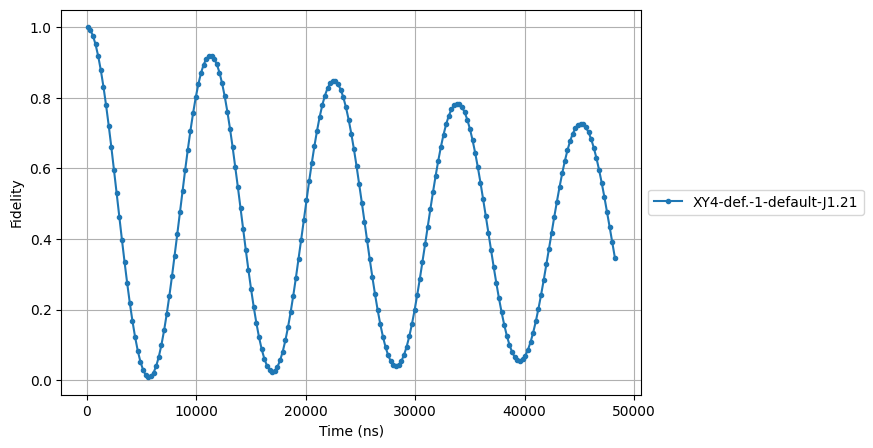

In [221]:
# Works for multiple circuits

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
# axes = np.atleast_1d(axes)
colors = plt.get_cmap('tab20')

for i, (circ_name, circ, J_results) in enumerate(zip(circuit_names, circuits, total_data)):
    for j, (J, fidelities) in enumerate(zip(J_inputs, J_results)):
        if J == 0.75:
            continue
        for k, case in enumerate(fidelities.keys()):
            # Don't forget to save or update the measure times
            moments = simulator.build_moments(circ)
            duration_2qb = duration_2qb_default / J
            measure_times = (
                np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
            )
            # Only plot every 6th point, once after each XY4 layer
            skip = 6
            ax.plot(
                measure_times[::skip], fidelities[case][::skip], 
                color=colors((j + i) % 2 + 2 * k), label=f"{circ_name}-{case}-J{J}", marker="."
            )
        
# ax.set_yscale("log")
# ax.set_ylim([-0.1, 1.1])
# ax.set_xticks(np.arange(0, 18, 1))
ax.set_xlabel("Time (ns)")
ax.set_ylabel("Fidelity")
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
# ax.set_yticks(np.arange(0, 0.4, 0.1))
ax.grid(True)

fig.subplots_adjust(hspace=1.25, right=0.85)
plt.show()

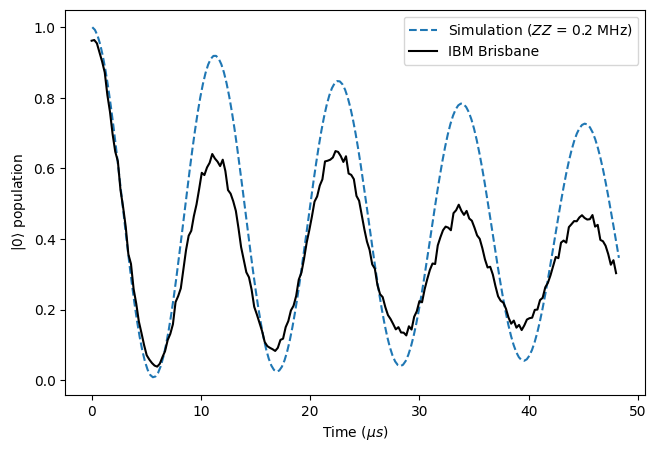

In [232]:
# Works for multiple circuits

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

# axes = np.atleast_1d(axes)
colors = plt.get_cmap('tab20')

for i, (circ_name, circ, J_results) in enumerate(zip(circuit_names, circuits, total_data)):
    for j, (J, fidelities) in enumerate(zip(J_inputs, J_results)):
        if J == 0.75:
            continue
        for k, case in enumerate(fidelities.keys()):
            # Don't forget to save or update the measure times
            moments = simulator.build_moments(circ)
            duration_2qb = duration_2qb_default / J
            measure_times = (
                np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
            )
            # Only plot every 6th point, once after each XY4 layer
            skip = 6
            ax.plot(
                measure_times[::skip] / 1e3, fidelities[case][::skip], 
                # color=colors((j + i) % 2 + 2 * k), 
                label="Simulation ($ZZ$ = 0.2 MHz)", 
                ls="--"
                # marker="."
            )

ax.plot(0.5 * xy4_data[1] / 1e3, xy4_data[0], color="black", ls="-", label="IBM Brisbane")
        
# ax.set_yscale("log")
# ax.set_ylim([-0.1, 1.1])
# ax.set_xticks(np.arange(0, 18, 1))
ax.set_xlabel(r"Time ($\mu s$)")
ax.set_ylabel(r"$|0\rangle$ population")
ax.legend(loc='upper right')
# ax.set_yticks(np.arange(0, 0.4, 0.1))
# ax.grid(True, which="major", axis="y")


# fig.subplots_adjust(hspace=1.25, right=0.85)
plt.show()

In [ ]:
# # Assumes a single circuit

# fig, axes = plt.subplots(len(J_results), 1, figsize=(8, 5))
# axes = np.atleast_1d(axes)

# for ax, J, fidelities in zip(axes.flatten(), J_inputs, J_results):
#     for case in cases:
#         # Don't forget to save or update the measure times
#         duration_2qb = duration_2qb_default / J
#         measure_times = (
#             np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
#         )
#         ax.plot(measure_times / duration_1qb / dt, fidelities[case], label=case, marker=".")
#     ax.set_title(f"J = {J}")
    
#     # ax.set_yscale("log")
#     # ax.set_xticks(np.arange(0, 18, 1))
#     ax.set_xlabel("Layers (Elapsed time / 1QB duration)")
#     ax.set_ylabel("Fidelity")
#     ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
#     # ax.set_yticks(np.arange(0, 0.4, 0.1))
#     ax.grid(True)

# fig.subplots_adjust(hspace=1.25, right=0.85)

## Other Plots

In [ ]:
with open("../playground/data_2024-11-19_16-04-53/J_results.pkl", "rb") as file:
    J_results_prev = pkl.load(file)

J_results_new = []
for prev, current in zip(J_results_prev, J_results):
    J_results_new.append({**prev, **current})

In [ ]:
# Extract final fidelities for each case and J value
J_results_local = J_results_new
cases = [case for case in J_results_local[0].keys() if case != "1-crosstalk, 2-robust"]

final_kl = {case: [] for case in cases}
for fidelities in J_results_local:
    for case in cases:
        final_kl[case].append(fidelities[case][-1])

# Define a professional color palette using matplotlib's colormap
colors = cm.get_cmap('tab10').colors

# Define patterns for the bars
patterns = ['/', '\\', 'x', '-', '.', '*']

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 4))

# Add horizontal gridlines
ax.yaxis.grid(True, which='both')

# Move the grid to the background
ax.set_axisbelow(True)

# Adjust bar width and spacing
bar_width = 0.15
group_spacing = 0.3
case_width = len(cases) - 1 if "decoherence limit" in cases else len(cases)
x = np.arange(len(J_inputs)) * (case_width * bar_width + group_spacing)

for i, (case, color, pattern) in enumerate(zip(cases, colors, patterns)):
    if case == "decoherence limit":
        continue
    else:
        ax.bar(x + i * bar_width, final_kl[case], bar_width, label=case, color=color, hatch=pattern)

ax.set_xlabel('J values')
ax.set_ylabel('Final Fidelity')
ax.set_title('TFIM Final Fidelity for Different Cases and J Values')
ax.set_xticks(x + bar_width * (len(cases) - 1) / 2)
ax.set_xticklabels(J_inputs)
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.set_ylim([0, 1])
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(0.1))
ax.yaxis.set_major_formatter('{x:.1f}')
ax.yaxis.set_minor_locator(mpl.ticker.MultipleLocator(0.05))

ax2 = ax.twinx()
ax2.plot(x + bar_width * (len(cases) - 2) / 2, final_kl["decoherence limit"], color="black", label="decoherence limit", marker="_", ms=75, lw=0)
ax2.set_ylim([0, 1])
ax2.set_yticks([])

# ax.set_yticks(np.arange(0, 1.1, 0.1))
fig.savefig(f"../playground/data_{dt_string}/final_fidelities.svg", dpi=300, bbox_inches="tight")

In [ ]:
# J_results_newer = J_results + J_results_new

In [ ]:
# J_inputs = [0.5, 1.0, 1.5, 2.0, 4.0]

# # Extract final fidelities for each case and J value
# cases = J_results_newer[0].keys()
# final_kl = {case: [] for case in cases}
# for fidelities in J_results_newer:
#     for case in cases:
#         final_kl[case].append(fidelities[case][-1])

# # Define a professional color palette using matplotlib's colormap
# colors = cm.get_cmap('tab10').colors

# # Define patterns for the bars
# patterns = ['/', '\\', 'x', '-', '.', '*']

# # Create the bar chart
# fig, ax = plt.subplots(figsize=(11, 4))

# # Add horizontal gridlines
# ax.yaxis.grid(True)

# # Move the grid to the background
# ax.set_axisbelow(True)

# # Adjust bar width and spacing
# bar_width = 0.1
# group_spacing = 0.4
# x = np.arange(len(J_inputs)) * (len(cases) * bar_width + group_spacing)

# for i, (case, color, pattern) in enumerate(zip(cases, colors, patterns)):
#     ax.bar(x + i * bar_width, final_kl[case], bar_width, label=case, color=color, hatch=pattern)

# ax.set_xlabel('J values')
# ax.set_ylabel('Final Fidelity')
# ax.set_title('TFIM Final Fidelity for Different Cases and J Values')
# ax.set_xticks(x + bar_width * (len(cases) - 1) / 2)
# ax.set_xticklabels(J_inputs)
# ax.legend()
# ax.set_ylim([0, 1])
# ax.set_yticks(np.arange(0, 1.1, 0.1))
# plt.show()

# KL Divergence

In [ ]:
# need the expected distribution for KL divergence
x = ps.qiskit_ground_state(4).evolve(U_goals[-1])
y_expected = np.abs(x.data) ** 2

loc = (
    lambda x: f"../playground/data_2024-10-29_22-38-03/J_{x}_crosstalk_True_dissipation_True/"
)

kl_divergences = []
for J in ["1.0", "1.5", "2.0", "4.0"]:
    kl_entry = {}
    for case in ["1-default, 2-default", "1-robust, 2-default", "1-robust, 2-rotary"]:
        with open(loc(J) + f"result_{case}.pkl", "rb") as file:
            J_results_1 = pkl.load(file)
            x = ps.qiskit_ground_state(4, open=True).evolve(J_results_1[-1])
            y_actual = x.probabilities(qargs=[0, 1, 2, 3])
            kl_entry[case] = np.sum(
                [yp * np.log(yp / yq) for yq, yp in zip(y_expected, y_actual)]
            )
    kl_divergences.append(kl_entry)

loc = (
    lambda x: f"../playground/data_2024-10-30_21-03-37/J_{x}_crosstalk_True_dissipation_True/"
)

for i, J in enumerate(["1.0", "1.5", "2.0", "4.0"]):
    for case in ["1-robust, 2-robust"]:
        with open(loc(J) + f"result_{case}.pkl", "rb") as file:
            J_results_1 = pkl.load(file)
            x = ps.qiskit_ground_state(4, open=True).evolve(J_results_1[-1])
            y_actual = x.probabilities(qargs=[0, 1, 2, 3])
            kl_divergences[i][case] = np.sum(
                [yp * np.log(yp / yq) for yq, yp in zip(y_expected, y_actual)]
            )

loc = (
    lambda x: f"../playground/data_2024-10-30_23-08-07/J_{x}_crosstalk_True_dissipation_True/"
)

for i, J in enumerate(["0.5"]):
    kl_entry = {}
    for case in ["1-default, 2-default", "1-robust, 2-default", "1-robust, 2-rotary", "1-robust, 2-robust"]:
        with open(loc(J) + f"result_{case}.pkl", "rb") as file:
            J_results_1 = pkl.load(file)
            x = ps.qiskit_ground_state(4, open=True).evolve(J_results_1[-1])
            y_actual = x.probabilities(qargs=[0, 1, 2, 3])
            kl_entry[case] = np.sum(
                [yp * np.log(yp / yq) for yq, yp in zip(y_expected, y_actual)]
            )
kl_divergences = [kl_entry] + kl_divergences

In [ ]:
J_inputs = [0.5, 1.0, 1.5, 2.0, 4.0]

# Extract final fidelities for each case and J value
final_kl = kl_divergences[0].keys()
final_kl = {case: [] for case in cases}
for kls in kl_divergences:
    for case in cases:
        final_kl[case].append(kls[case])

# Define a professional color palette using matplotlib's colormap
colors = cm.get_cmap('tab10').colors

# Define patterns for the bars
patterns = ['/', '\\', 'x', '-', '.', '*']

# Create the bar chart
fig, ax = plt.subplots(figsize=(11, 4))

# Add horizontal gridlines
ax.yaxis.grid(True)

# Move the grid to the background
ax.set_axisbelow(True)

# Adjust bar width and spacing
bar_width = 0.1
group_spacing = 0.4
x = np.arange(len(J_inputs)) * (len(cases) * bar_width + group_spacing)

for i, (case, color, pattern) in enumerate(zip(cases, colors, patterns)):
    ax.bar(x + i * bar_width, final_kl[case], bar_width, label=case, color=color, hatch=pattern)

ax.set_xlabel('J values')
ax.set_ylabel('KL Divergence')
ax.set_title('TFIM Final KL Divergence for Different Cases and J Values')
ax.set_xticks(x + bar_width * (len(cases) - 1) / 2)
ax.set_xticklabels(J_inputs)
ax.legend()
# ax.set_ylim([5e-4, 2])
# ax.set_yscale("log")
# ax.set_yticks(np.arange(-0.1, 0.5, 0.1))
plt.show()